In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("data_clean", exist_ok=True)
os.makedirs("images", exist_ok=True)

q1_2019 = pd.read_excel("data_raw/Divvy_Trips_2019_Q1.xlsx")
q1_2020 = pd.read_excel("data_raw/Divvy_Trips_2020_Q1.xlsx")

print("2019 Q1 shape:", q1_2019.shape)
print("2019 columns:", list(q1_2019.columns))
print("\n2020 Q1 shape:", q1_2020.shape)
print("2020 columns:", list(q1_2020.columns))

2019 Q1 shape: (365069, 12)
2019 columns: ['trip_id', 'start_time', 'end_time', 'bikeid', 'tripduration', 'from_station_id', 'from_station_name', 'to_station_id', 'to_station_name', 'usertype', 'gender', 'birthyear']

2020 Q1 shape: (426887, 13)
2020 columns: ['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']


In [4]:
q1_2019 = q1_2019.rename(columns={
    "trip_id": "ride_id",
    "bikeid": "rideable_type",
    "start_time": "started_at",
    "end_time": "ended_at",
    "from_station_name": "start_station_name",
    "from_station_id": "start_station_id",
    "to_station_name": "end_station_name",
    "to_station_id": "end_station_id",
    "usertype": "member_casual"
})

common_cols = [
    "ride_id", "rideable_type", "started_at", "ended_at",
    "start_station_name", "start_station_id", 
    "end_station_name", "end_station_id", "member_casual"
]

q1_2019["ride_id"] = q1_2019["ride_id"].astype(str)
q1_2019["rideable_type"] = q1_2019["rideable_type"].astype(str)
q1_2020["ride_id"] = q1_2020["ride_id"].astype(str)
q1_2020["rideable_type"] = q1_2020["rideable_type"].astype(str)

df = pd.concat([q1_2019, q1_2020], ignore_index=True)

df["member_casual"] = df["member_casual"].replace({
    "Subscriber": "member", 
    "Customer": "casual"
    })

print("combined table size:", df.shape)
print("\nRider types:")
print(df["member_casual"].value_counts())

combined table size: (791956, 16)

Rider types:
member_casual
member    720313
casual     71643
Name: count, dtype: int64


In [8]:
df["started_at"] = pd.to_datetime(df["started_at"])
df["ended_at"] = pd.to_datetime(df["ended_at"])

# Calculate ride duration in minutes
df["ride_length_min"] = (df["ended_at"] - df["started_at"]).dt.total_seconds() / 60

# Check for data problems before cleaning
initial_rows = len(df)
dups = df.duplicated(subset=["ride_id"]).sum()
hq_qr = (df["start_station_name"] == "HQ QR").sum()
neg_or_zero = (df["ride_length_min"] <= 0).sum()
over_24h = (df["ride_length_min"] > 1440).sum()

print(f"Initial rows: {initial_rows:,}")
print(f"Duplicate ride_ids: {dups:,}")
print(f"Test station 'HQ QR' rides: {hq_qr:,}")
print(f"Zero or negative duration rides: {neg_or_zero:,}")
print(f"Extreme outliers (>24 hours): {over_24h:,}")

# Keep only clean, valid rides
df_clean = df.drop_duplicates(subset=["ride_id"]).copy()
df_clean = df_clean[
    (df_clean["start_station_name"] != "HQ QR") &
    (df_clean["ride_length_min"] > 0) &
    (df_clean["ride_length_min"] <= 1440)
].dropna(subset=["started_at", "ended_at", "member_casual"])

print(f"\nCleaned rows remaining: {len(df_clean):,}")
print(f"Total rows removed: {initial_rows - len(df_clean):,}")

# Add day of week (Monday -> Sunday) and hour of day (0 -> 23)
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df_clean["day_of_week"] = pd.Categorical(
    df_clean["started_at"].dt.day_name(),
    categories=day_order,
    ordered=True
)
df_clean["hour"] = df_clean["started_at"].dt.hour
df_clean["year_month"] = df_clean["started_at"].dt.to_period("M").astype(str)

Initial rows: 791,956
Duplicate ride_ids: 0
Test station 'HQ QR' rides: 3,767
Zero or negative duration rides: 210
Extreme outliers (>24 hours): 482

Cleaned rows remaining: 787,707
Total rows removed: 4,249


In [11]:
summary_stats = df_clean.groupby("member_casual")["ride_length_min"].agg(
    total_rides="count",
    mean_duration_min="mean",
    median_duration_min="median",
    max_duration_min="max"
).reset_index()
summary_stats["share_pct"] = (summary_stats["total_rides"] / summary_stats["total_rides"].sum()) * 100
print("=== Overall Summary ===")
print(summary_stats.round(2))

# 2. Rides & average duration by Day of the Week
daily_stats = df_clean.groupby(["day_of_week", "member_casual"], observed=False)["ride_length_min"].agg(
    total_rides="count",
    avg_duration_min="mean"
).reset_index()
print("\n=== By Day of Week ===")
print(daily_stats.round(2))

# 3. Rides by Hour of Day
hourly_stats = df_clean.groupby(["hour", "member_casual"])["ride_id"].count().reset_index(name="total_rides")

# 4. Top 10 Start Stations for Casual Riders
top_casual_stations = (
    df_clean[df_clean["member_casual"] == "casual"]["start_station_name"]
    .value_counts()
    .head(10)
    .reset_index()
)
top_casual_stations.columns = ["start_station_name", "casual_rides"]
print("\n=== Top 10 Casual Start Stations ===")
print(top_casual_stations)

# Save small summary files into data_clean/
summary_stats.to_csv("data_clean/overall_summary.csv", index=False)
daily_stats.to_csv("data_clean/daily_summary.csv", index=False)
hourly_stats.to_csv("data_clean/hourly_summary.csv", index=False)
top_casual_stations.to_csv("data_clean/top_casual_stations.csv", index=False)
print("\nSummary CSVs saved to data_clean/!")

=== Overall Summary ===
  member_casual  total_rides  mean_duration_min  median_duration_min  \
0        casual        67582              38.38                23.13   
1        member       720125              11.41                 8.47   

   max_duration_min  share_pct  
0           1435.92       8.58  
1           1433.07      91.42  

=== By Day of Week ===
   day_of_week member_casual  total_rides  avg_duration_min
0       Monday        casual         5569             34.43
1       Monday        member       110412             11.10
2      Tuesday        casual         7288             35.56
3      Tuesday        member       127946             11.32
4    Wednesday        casual         7655             41.12
5    Wednesday        member       121878             11.17
6     Thursday        casual         7105             35.27
7     Thursday        member       125198             11.07
8       Friday        casual         7971             37.12
9       Friday        member       1

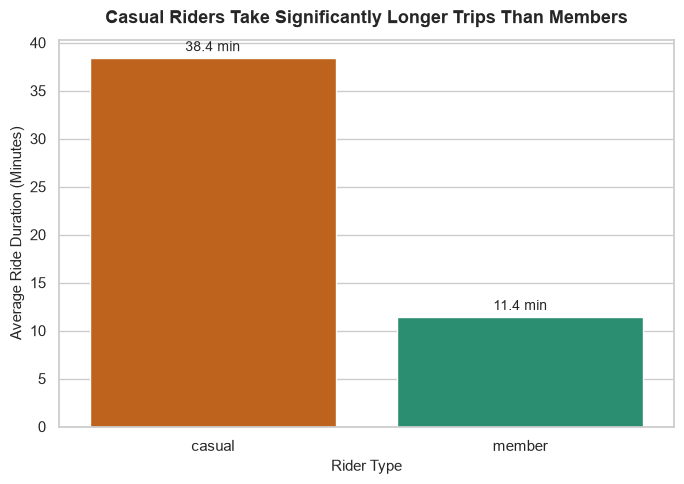

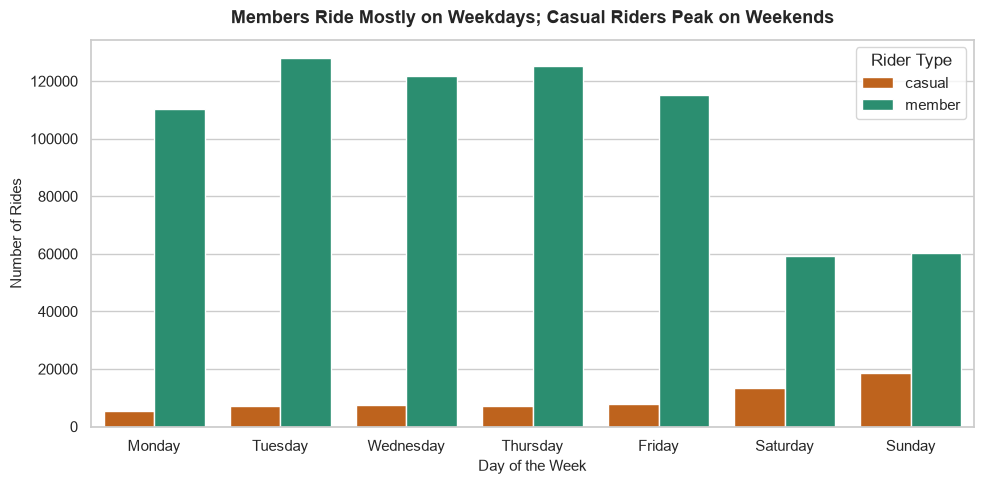

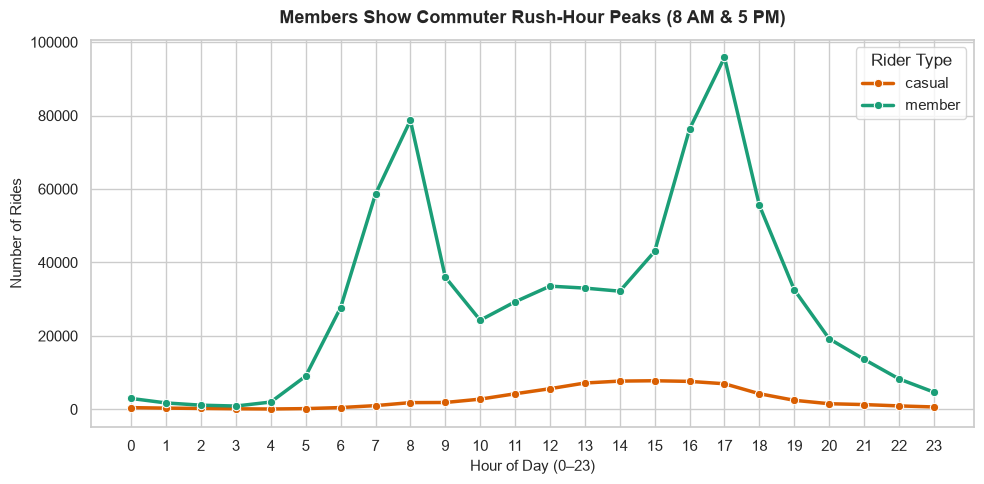

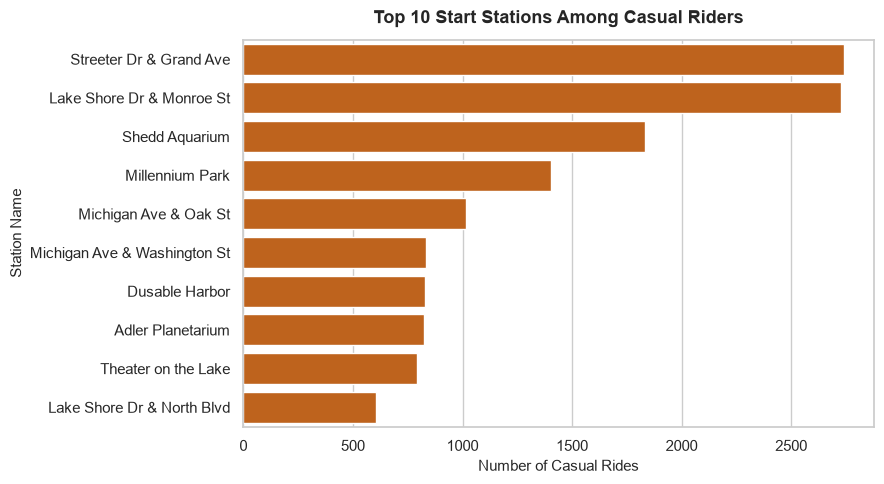

In [12]:
sns.set(style="whitegrid")
palette = {"member": "#1b9e77", "casual": "#d95f02"}

plt.figure(figsize=(7, 5))
ax = sns.barplot(data=summary_stats, x="member_casual", y="mean_duration_min", hue="member_casual", palette=palette, legend=False)
plt.title("Casual Riders Take Significantly Longer Trips Than Members", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Rider Type", fontsize=11)
plt.ylabel("Average Ride Duration (Minutes)", fontsize=11)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f min", padding=3, fontsize=10)
plt.tight_layout()
plt.savefig("images/avg_ride_duration.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=daily_stats, x="day_of_week", y="total_rides", hue="member_casual", palette=palette)
plt.title("Members Ride Mostly on Weekdays; Casual Riders Peak on Weekends", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Day of the Week", fontsize=11)
plt.ylabel("Number of Rides", fontsize=11)
plt.legend(title="Rider Type")
plt.tight_layout()
plt.savefig("images/rides_by_day.png", dpi=300)
plt.show()

# Chart 3: Hourly Ride Trends
plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_stats, x="hour", y="total_rides", hue="member_casual", palette=palette, marker="o", linewidth=2.5)
plt.title("Members Show Commuter Rush-Hour Peaks (8 AM & 5 PM)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Hour of Day (0–23)", fontsize=11)
plt.ylabel("Number of Rides", fontsize=11)
plt.xticks(range(0, 24))
plt.legend(title="Rider Type")
plt.tight_layout()
plt.savefig("images/rides_by_hour.png", dpi=300)
plt.show()

# Chart 4: Top 10 Start Stations for Casual Riders
plt.figure(figsize=(9, 5))
sns.barplot(data=top_casual_stations, y="start_station_name", x="casual_rides", color="#d95f02")
plt.title("Top 10 Start Stations Among Casual Riders", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Number of Casual Rides", fontsize=11)
plt.ylabel("Station Name", fontsize=11)
plt.tight_layout()
plt.savefig("images/top_casual_stations.png", dpi=300)
plt.show()